In [18]:
# Install ucimlrepo
!pip install ucimlrepo

Task 1: Load the dataset into a Pandas DataFrame.

In [19]:

from ucimlrepo import fetch_ucirepo 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
    
# Fetch the UCI Heart Disease dataset (id=45)
heart_disease = fetch_ucirepo(id=45)

# Combine features and target into one DataFrame
X = heart_disease.data.features
y = heart_disease.data.targets.rename(columns={"num": "target"})
df = pd.concat([X, y], axis=1)


* Task 2: Use structural inspection methods (head(), info(), describe()) to analyze continuous and categorical features.

In [20]:
# Display Data Frame Head
print("\n --- DF Head ---")
print(df.head())

# Display Data Frame Info
print("\n --- DF INFO ---")
df.info()



 --- DF Head ---
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  target  
0  0.0   6.0       0  
1  3.0   3.0       2  
2  2.0   7.0       1  
3  0.0   3.0       0  
4  0.0   3.0       0  

 --- DF INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  


In [21]:
# Seperate Numeric and Categorical Features
numerical_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

print("\n--- Continuous Feature Summary ---")
display(df[numerical_features].describe())

print("\n--- Categorical Feature Summary ---")
display(df[categorical_features].astype("category").describe())


--- Continuous Feature Summary ---


,age,trestbps,chol,thalach,oldpeak
count,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,131.689769,246.693069,149.607261,1.039604
std,9.038662,17.599748,51.776918,22.875003,1.161075
min,29.000000,94.000000,126.000000,71.000000,0.000000
25%,48.000000,120.000000,211.000000,133.500000,0.000000
50%,56.000000,130.000000,241.000000,153.000000,0.800000
75%,61.000000,140.000000,275.000000,166.000000,1.600000
max,77.000000,200.000000,564.000000,202.000000,6.200000



--- Categorical Feature Summary ---


,sex,cp,fbs,restecg,exang,slope,ca,thal
count,303,303,303,303,303,303,299.0,301.0
unique,2,4,2,3,2,3,4.0,3.0
top,1,4,0,0,0,1,0.0,3.0
freq,206,144,258,151,204,142,176.0,166.0


* Task 3: Quantify and handle any missing or implicit missing values across the columns (checking for non-standard placeholders such as ? strings) and implement a structured imputation strategy using Scikit-Learn's SimpleImputer.

In [22]:
from sklearn.impute import SimpleImputer

print("--- Missing Values (?) ---")
print((df == '?').sum())

# find Null values 
print("--- Null Values ---")
df.isnull().sum()


--- Missing Values (?) ---
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
--- Null Values ---


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [23]:
#  Imputer for Numeric and Catagorical 
num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

df[numerical_features] = num_imputer.fit_transform(df[numerical_features])
df[categorical_features] = cat_imputer.fit_transform(df[categorical_features])

# find Null values 
print("--- Null Values ---")
df.isnull().sum()

--- Null Values ---


,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


* Task 4: Isolate numerical and categorical features, then build a Scikit-Learn ColumnTransformer and Pipeline that applies appropriate scaling (StandardScaler or MinMaxScaler) to numerical columns and encoding (OneHotEncoder) to categorical columns.

In [24]:
# Import Libs 
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline, Pipeline

X = df[numerical_features + categorical_features]
y = (df["target"] > 0).astype(int)

# Numeric Pipeline 
num_pipeline = make_pipeline(
    SimpleImputer(strategy="median"), 
    StandardScaler())

# Catagoric Pipeline 
cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore"))

# Perform Column Transformer 
preprocessing = ColumnTransformer([
    ("num", num_pipeline, numerical_features),
    ("cat", cat_pipeline, categorical_features),
])

* Task 5: Instantiate and train a Support Vector Classifier (SVC) configured with kernel='rbf' and probability=True within your pipeline, then evaluate performance using a confusion matrix, classification report, and ROC-AUC curve.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Create a pipeline combining feature scaling and the Support Vector Classifier
svm_clf = Pipeline([
    ("preprocessing", preprocessing),
    ("svc", SVC(kernel="rbf", probability=True, random_state=42))
])

print("SVM Pipeline successfully created:")
print(svm_clf)

svm_clf.fit(X_train, y_train)

y_pred = svm_clf.predict(X_test)
y_proba = svm_clf.predict_proba(X_test)[:, 1]


SVM Pipeline successfully created:
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                            

Plots: confusion matrix, classification report, and ROC-AUC curve.

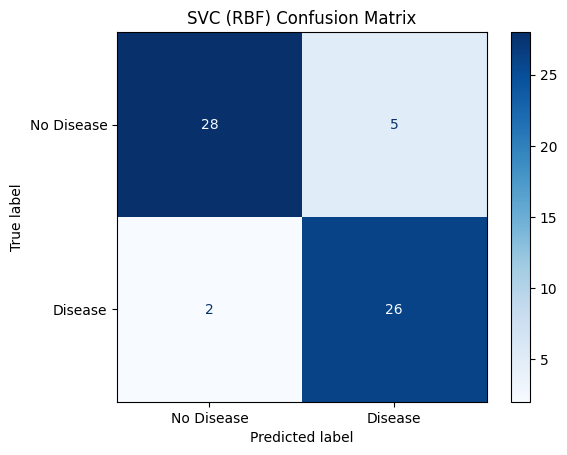

--- SVC (RBF) Classification Report ---
              precision    recall  f1-score   support

  No Disease       0.93      0.85      0.89        33
     Disease       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

SVC (RBF) ROC-AUC: 0.9643


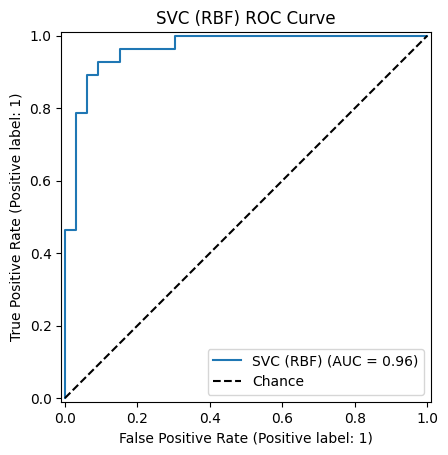

In [26]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_auc_score, RocCurveDisplay
)

def evaluate_model(model, name):

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["No Disease", "Disease"]).plot(cmap="Blues")
    plt.title(f"{name} Confusion Matrix")
    plt.show()

    # Classification Report
    print(f"--- {name} Classification Report ---")
    print(classification_report(y_test, y_pred, target_names=["No Disease", "Disease"]))

    # ROC-AUC curve
    auc = roc_auc_score(y_test, y_proba)
    print(f"{name} ROC-AUC: {auc:.4f}")
    RocCurveDisplay.from_predictions(y_test, y_proba, name=name)
    plt.plot([0, 1], [0, 1], "k--", label="Chance")
    plt.title(f"{name} ROC Curve")
    plt.legend()
    plt.show()

evaluate_model(svm_clf, "SVC (RBF)")


* Task 6: Instantiate and train a Decision Tree Classifier (DecisionTreeClassifier) within your pipeline, and evaluate its performance using identical metrics to compare against your SVC model.

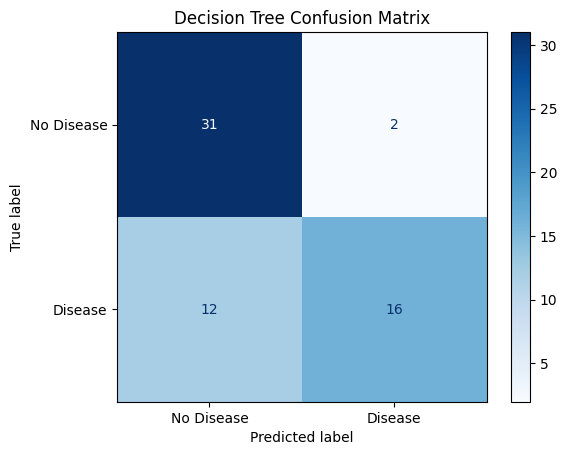

--- Decision Tree Classification Report ---
              precision    recall  f1-score   support

  No Disease       0.72      0.94      0.82        33
     Disease       0.89      0.57      0.70        28

    accuracy                           0.77        61
   macro avg       0.80      0.76      0.76        61
weighted avg       0.80      0.77      0.76        61

Decision Tree ROC-AUC: 0.8203


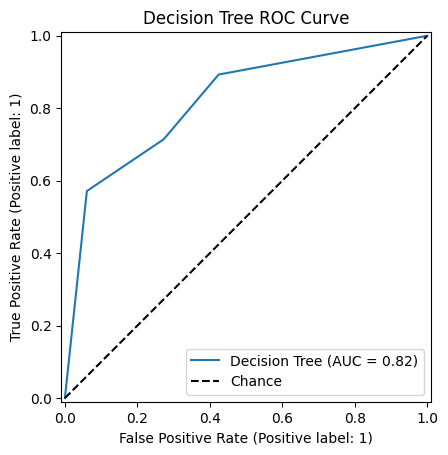

In [27]:
from sklearn.tree import DecisionTreeClassifier

tree_clf = Pipeline([
    ("preprocessing", preprocessing),
    ("tree", DecisionTreeClassifier(max_depth=2, random_state=42))
])

tree_clf.fit(X_train, y_train)

# plot
evaluate_model(tree_clf, "Decision Tree")

* Task 7: Perform hyperparameter tuning using GridSearchCV on your SVC pipeline (exploring parameters such as C and gamma) to optimize cross-validation performance.

Best parameters: {'svc__C': 10, 'svc__gamma': 0.001}
Best CV ROC-AUC: 0.8947


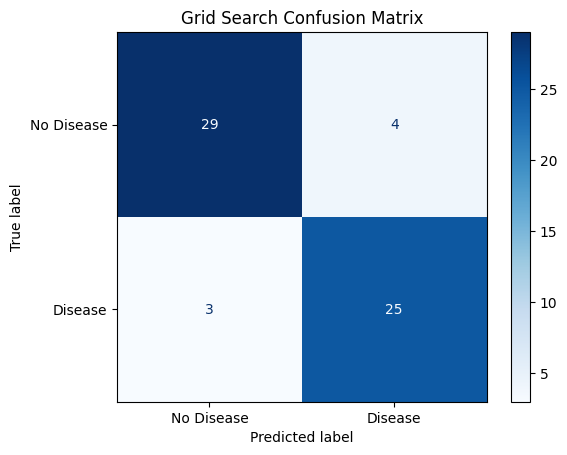

--- Grid Search Classification Report ---
              precision    recall  f1-score   support

  No Disease       0.91      0.88      0.89        33
     Disease       0.86      0.89      0.88        28

    accuracy                           0.89        61
   macro avg       0.88      0.89      0.88        61
weighted avg       0.89      0.89      0.89        61

Grid Search ROC-AUC: 0.9643


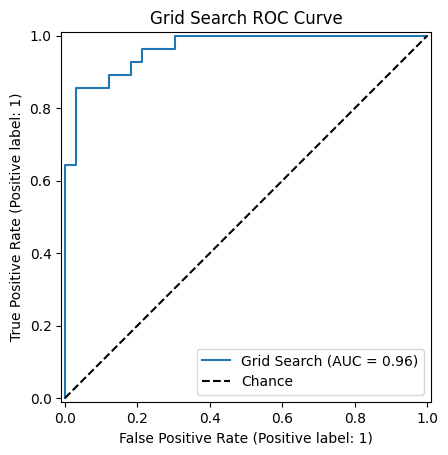

In [28]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.001, 0.01, 0.1, 1]
}

grid_search = GridSearchCV(
    svm_clf,              # the full pipeline (preprocessing + SVC)
    param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV ROC-AUC:", round(grid_search.best_score_, 4))

# Plot
evaluate_model(grid_search, "Grid Search")

* Task 8: Generate a decision tree visualization (plot_tree) or inspect feature importances to interpret how the model separates patients with heart disease from healthy patients.


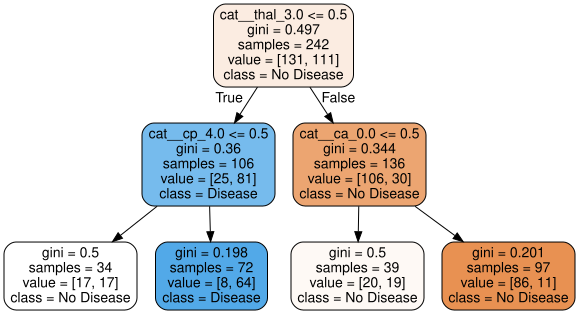

In [29]:
from sklearn.tree import export_graphviz
from graphviz import Source


fitted_tree = tree_clf.named_steps["tree"]
feature_names = tree_clf.named_steps["preprocessing"].get_feature_names_out()
class_names = ["No Disease", "Disease"]

export_graphviz(
    fitted_tree,
    out_file="heart_tree.dot",
    feature_names=feature_names,
    class_names=class_names,
    max_depth=3,
    rounded=True,
    filled=True
)
Source.from_file("heart_tree.dot")